# StreamFlix - Phase 2: Exploratory Data Analysis

This notebook creates the ten required charts and saves them as PNG files in the charts folder.

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)

subscribers = pd.read_csv("subscribers.csv", parse_dates=["signup_date", "churn_date"])
titles = pd.read_csv("titles.csv")
watch_history = pd.read_csv("watch_history.csv", parse_dates=["watch_date"])
ratings = pd.read_csv("ratings.csv")
reviews = pd.read_csv("reviews.csv")

watch_history["watch_hours"] = watch_history["watch_duration_min"] / 60
watch_history["month"] = watch_history["watch_date"].dt.to_period("M").astype(str)

watch_data = watch_history.merge(
    titles[["title_id", "title_name", "type", "primary_genre"]],
    on="title_id",
    how="left"
)
watch_data = watch_data.merge(
    subscribers[["subscriber_id", "country", "age"]],
    on="subscriber_id",
    how="left"
)

print("EDA data loaded")


EDA data loaded


## Chart 1 - Monthly viewing volume

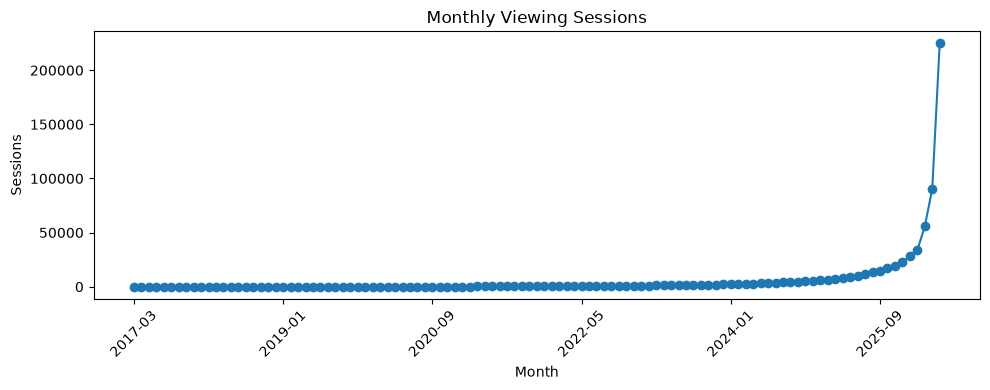

In [3]:
monthly_sessions = watch_history.groupby("month").size()
monthly_sessions.plot(kind="line", figsize=(10, 4), marker="o", title="Monthly Viewing Sessions")
plt.xlabel("Month")
plt.ylabel("Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/01_monthly_sessions.png")
plt.show()


## Chart 2 - Monthly watch hours

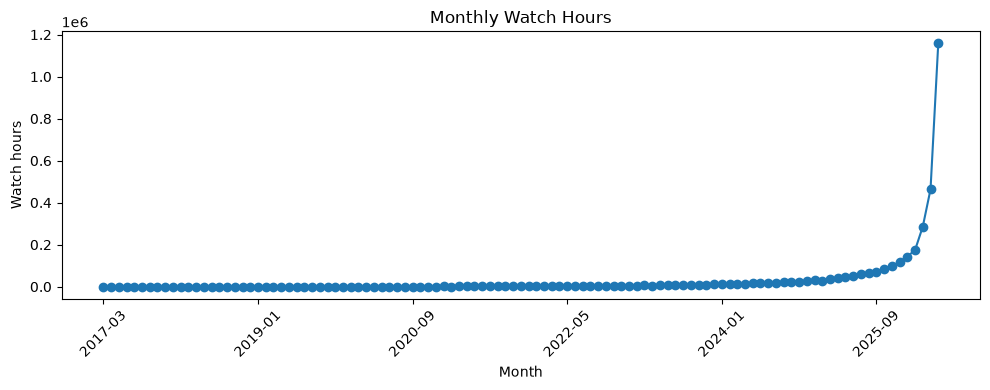

In [4]:
monthly_hours = watch_history.groupby("month")["watch_hours"].sum()
monthly_hours.plot(kind="line", figsize=(10, 4), marker="o", title="Monthly Watch Hours")
plt.xlabel("Month")
plt.ylabel("Watch hours")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/02_watch_hours_yoy.png")
plt.show()


## Chart 3 - Genre share of watch hours

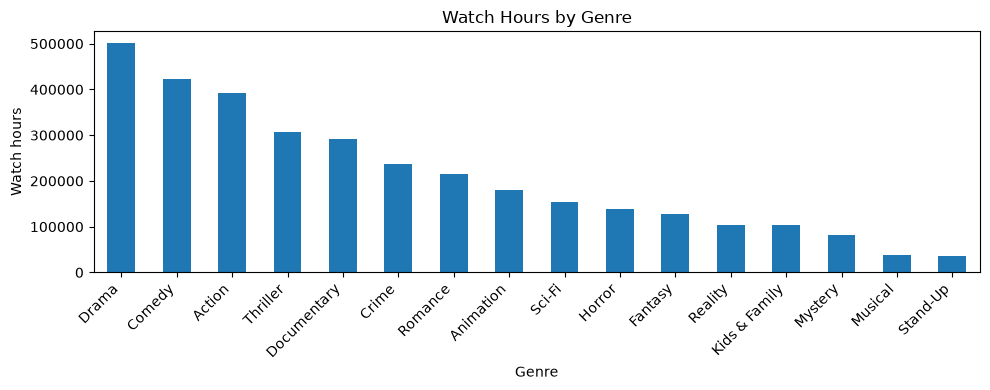

In [5]:
genre_hours = watch_data.groupby("primary_genre")["watch_hours"].sum().sort_values(ascending=False)
genre_hours.plot(kind="bar", figsize=(10, 4), title="Watch Hours by Genre")
plt.xlabel("Genre")
plt.ylabel("Watch hours")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/03_genre_share_hours.png")
plt.show()


## Chart 4 - Movies versus TV Shows

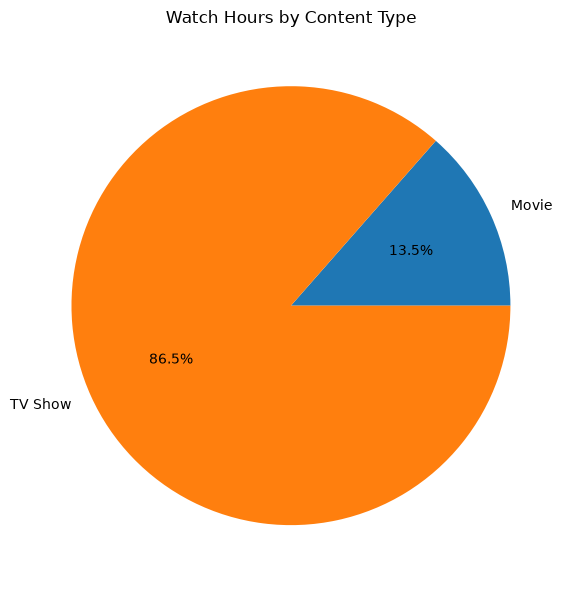

In [6]:
type_hours = watch_data.groupby("type")["watch_hours"].sum()
type_hours.plot(kind="pie", figsize=(6, 6), autopct="%.1f%%", title="Watch Hours by Content Type")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/04_type_split_donut.png")
plt.show()


## Chart 5 - Top 10 countries by watch hours

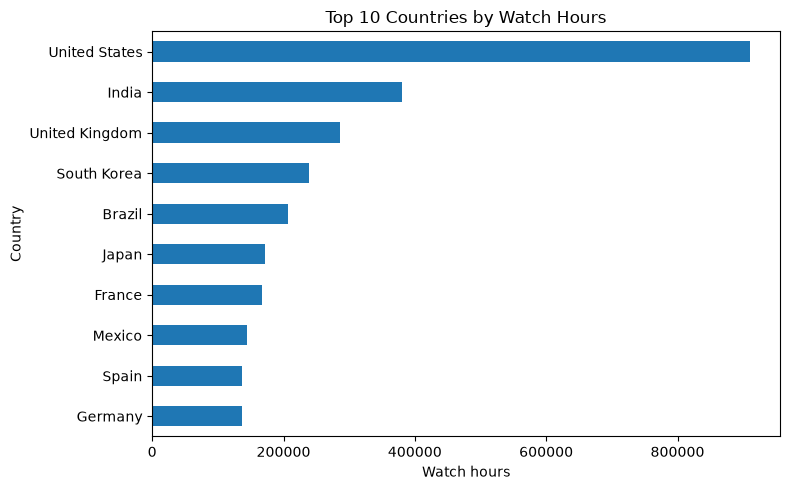

In [7]:
country_hours = watch_data.groupby("country")["watch_hours"].sum().nlargest(10).sort_values()
country_hours.plot(kind="barh", figsize=(8, 5), title="Top 10 Countries by Watch Hours")
plt.xlabel("Watch hours")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("charts/05_top10_countries.png")
plt.show()


## Chart 6 - Subscriber plan distribution

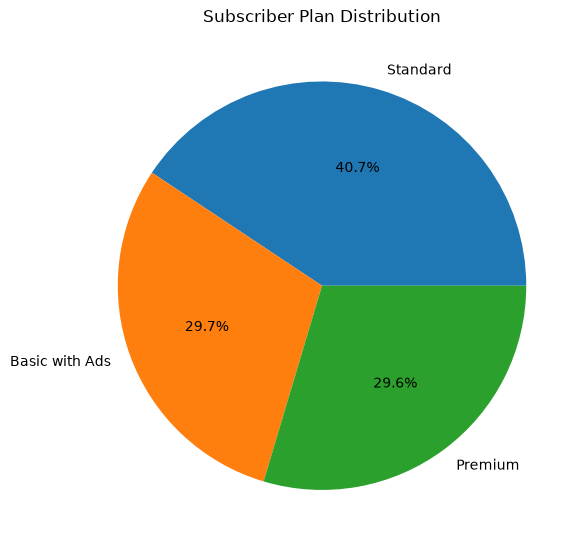

In [8]:
plan_counts = subscribers["plan_type"].value_counts()
plan_counts.plot(kind="pie", figsize=(6, 6), autopct="%.1f%%", title="Subscriber Plan Distribution")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/06_plan_distribution.png")
plt.show()


## Chart 7 - Device usage

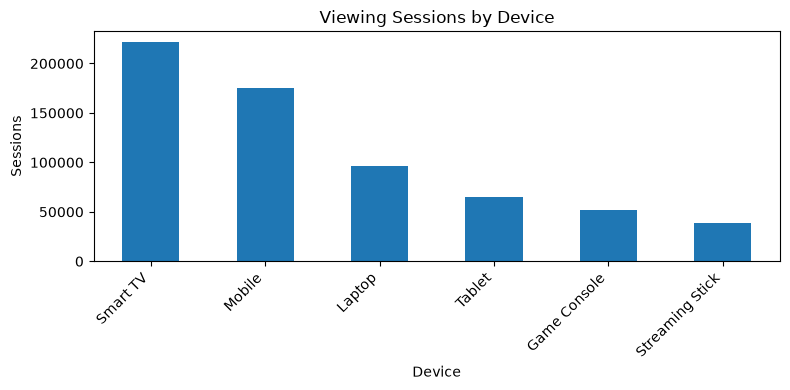

In [9]:
device_counts = watch_history["device"].value_counts()
device_counts.plot(kind="bar", figsize=(8, 4), title="Viewing Sessions by Device")
plt.xlabel("Device")
plt.ylabel("Sessions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/07_device_usage.png")
plt.show()


## Chart 8 - Subscriber age distribution

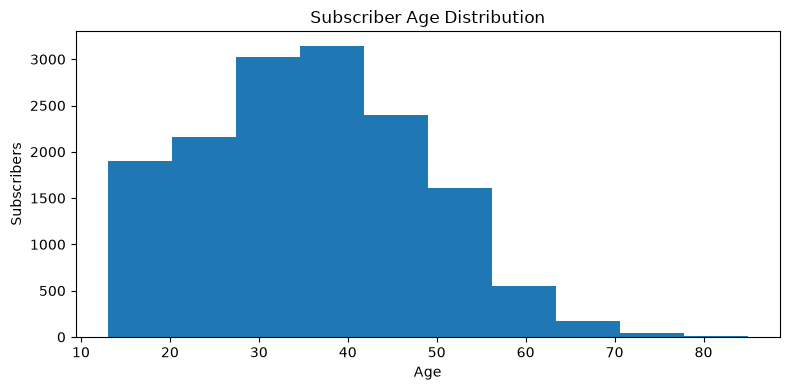

In [10]:
subscribers["age"].plot(kind="hist", bins=10, figsize=(8, 4), title="Subscriber Age Distribution")
plt.xlabel("Age")
plt.ylabel("Subscribers")
plt.tight_layout()
plt.savefig("charts/08_age_distribution.png")
plt.show()


## Chart 9 - Completion rate by genre

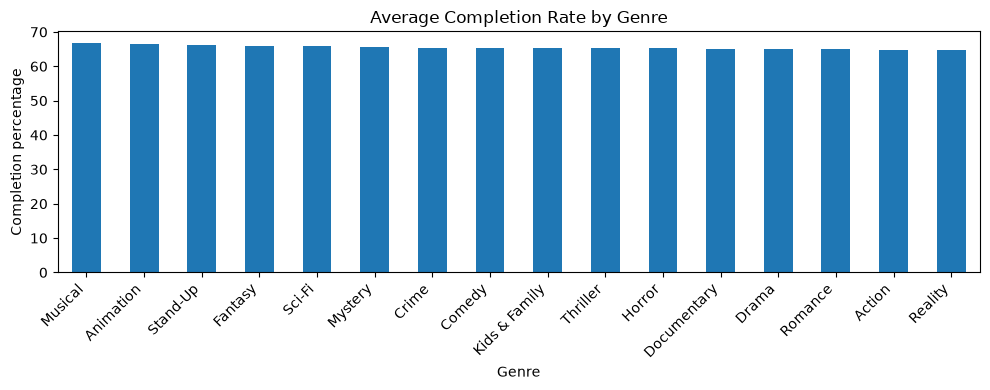

In [11]:
genre_completion = watch_data.groupby("primary_genre")["completion_pct"].mean().sort_values(ascending=False)
genre_completion.plot(kind="bar", figsize=(10, 4), title="Average Completion Rate by Genre")
plt.xlabel("Genre")
plt.ylabel("Completion percentage")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("charts/09_completion_by_genre.png")
plt.show()


## Chart 10 - Review sentiment

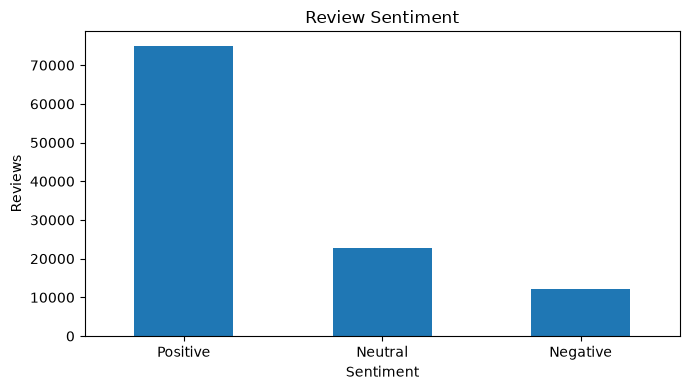

In [12]:
sentiment_counts = reviews["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).fillna(0)
sentiment_counts.plot(kind="bar", figsize=(7, 4), title="Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("charts/10_review_sentiment.png")
plt.show()


## Saved charts

In [13]:
print("Charts saved:")
for filename in sorted(os.listdir("charts")):
    print(filename)


Charts saved:
01_monthly_sessions.png
02_watch_hours_yoy.png
03_genre_share_hours.png
04_type_split_donut.png
05_top10_countries.png
06_plan_distribution.png
07_device_usage.png
08_age_distribution.png
09_completion_by_genre.png
10_review_sentiment.png


## Phase 2 Summary

- The exploratory analysis produced all ten required charts covering viewing volume, watch hours, genre mix, content type, geography, plan mix, device usage, subscriber age, completion by genre, and review sentiment.
- The charts provide the main descriptive view of StreamFlix engagement: how viewing changes over time, which content and audience segments contribute watch hours, and where completion and sentiment differ across categories.
- These visual patterns establish the context for the KPI calculations in Phase 3, particularly the interpretation of total watch hours, completion, content concentration, originals usage, and subscriber activity.
- All ten chart files were saved successfully in the `charts` folder, so the EDA outputs are available for reporting and downstream review.